<a href="https://colab.research.google.com/github/KhytsenkoIgor/python-data-analysis-tasks/blob/main/HW_16_2_%D0%9F%D1%80%D0%BE%D0%B3%D0%BD%D0%BE%D0%B7%D1%83%D0%B2%D0%B0%D0%BD%D0%BD%D1%8F_%D0%BA%D1%80%D0%B5%D0%B4%D0%B8%D1%82%D0%BD%D0%BE%D0%B3%D0%BE_%D1%80%D0%B8%D0%B7%D0%B8%D0%BA%D1%83.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнє завдання: Прогнозування кредитного ризику

## Мета завдання
Застосувати знання з лекції для побудови моделі логістичної регресії, що прогнозує ймовірність дефолту за кредитом, іншими словами, що людина не поверне кредит. Ви пройдете весь цикл: від дослідницького аналізу до оцінки якості класифікаційної моделі.

## Опис датасету
**Credit Risk Dataset** містить інформацію про 32,000+ позичальників з такими параметрами:
- **person_age**: Вік позичальника
- **person_income**: Річний дохід
- **person_home_ownership**: Тип володіння житлом
- **person_emp_length**: Стаж роботи (в роках)
- **loan_intent**: Мета кредиту
- **loan_grade**: Кредитний рейтинг (A - кращий, F - гірший)
- **loan_amnt**: Сума кредиту
- **loan_int_rate**: Процентна ставка
- **loan_status**: Статус кредиту (0 = сплачено, 1 = дефолт) - **цільова змінна**
- **loan_percent_income**: Відношення кредиту до доходу
- **cb_person_default_on_file**: Історія дефолтів (Y/N)
- **cb_person_cred_hist_length**: Довжина кредитної історії

---

## Завдання 1: Завантаження та перший огляд даних (1 бал)

**Що потрібно зробити:**
1. Завантажте дані з файлу `credit_risk_dataset.csv`
2. Виведіть розмір датасету
3. Покажіть перші 5 рядків
4. Виведіть загальну інформацію про дані (кількість записів, типи колонок)
5. Перевірте розподіл цільової змінної (відсотк даних для кожного класу)

Дайте висновок, це задача збалансованої чи незбалансованої класифікації.


**1.1 Завантаження даних з файлу `credit_risk_dataset.csv`**

In [21]:
import pandas as pd

df = pd.read_csv('credit_risk_dataset.csv')

**1.2 Розмір датасету**

In [22]:
print("Розмір датасету:", df.shape)

Розмір датасету: (32581, 12)


**1.3 Перші 5 рядків**

In [23]:
display(df.head())

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


**1.4 Загальна інформацію про дані (кількість записів, типи колонок)**

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


**1.5 Розподіл цільової змінної у відсотках**

In [25]:
print((df['loan_status'].value_counts(normalize=True) * 100).round(2))

loan_status
0    78.18
1    21.82
Name: proportion, dtype: float64


**Висновок:**

*   Це задача незбалансованої бінарної класифікації, класи розподілені нерівномірно: 78,18%  кредити без дефолту (0), 21,82%  кредити з дефолтом (1). Такий дисбаланс необхідно враховувати під час навчання та оцінювання моделі.



---

## Завдання 2: Дослідницький аналіз даних (EDA) (4 бали)

**Що потрібно зробити:**
1. Обчисліть відсоток пропущених значень в колонках. За наявності пропущених значень - заповніть їх медіаною для числових колонок і найбільш частим значеннмя для категоріальних.
2. Проаналізуйте розподіл числових змінних.
3. Знайдіть та обробіть викиди в колонці person_income з допомогою [Interquartile range](https://uk.wikipedia.org/wiki/%D0%9C%D1%96%D0%B6%D0%BA%D0%B2%D0%B0%D1%80%D1%82%D0%B8%D0%BB%D1%8C%D0%BD%D0%B8%D0%B9_%D1%80%D0%BE%D0%B7%D0%BC%D0%B0%D1%85).
4. Проаналізуйте категоріальні змінні відносно цільової та частоту зустрічання різних значень в них.
5. Візуалізуйте взаємозв'язок ознак з цільовою змінною.


**2.1 Перевірка та заповнення пропущених значень**

In [26]:

# Відсоток пропущених значень
print((df.isnull().mean() * 100).round(2))

# Заповнення числових колонок медіаною
for col in df.select_dtypes(include='number').columns:
    df[col] = df[col].fillna(df[col].median())

# Заповнення категоріальних колонок модою
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].fillna(df[col].mode()[0])

# Перевірка після заповнення
print("\nПропуски після заповнення:")
print(df.isnull().sum())


person_age                    0.00
person_income                 0.00
person_home_ownership         0.00
person_emp_length             2.75
loan_intent                   0.00
loan_grade                    0.00
loan_amnt                     0.00
loan_int_rate                 9.56
loan_status                   0.00
loan_percent_income           0.00
cb_person_default_on_file     0.00
cb_person_cred_hist_length    0.00
dtype: float64

Пропуски після заповнення:
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64


In [27]:

# Завантажуємо початкові дані
df_original = pd.read_csv('credit_risk_dataset.csv')

# Формуємо таблицю пропусків
result = pd.DataFrame({
    'Пропуски': df_original.isnull().sum(),
    'Відсоток, %': (df_original.isnull().mean() * 100).round(2)})

# Показуємо лише колонки з пропусками
display(result[result['Пропуски'] > 0])


,Пропуски,"Відсоток, %"
person_emp_length,895,2.75
loan_int_rate,3116,9.56


**2.2 Аналіз розподілу числових змінних**



### 2.2.1  Описова статистика








In [28]:

# Статистика числових змінних
display(df.select_dtypes(include='number').describe().round(2))


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.00,32581.00,32581.00,32581.00,32581.00,32581.00,32581.00,32581.00
mean,27.73,66074.85,4.77,9589.37,11.01,0.22,0.17,5.80
std,6.35,61983.12,4.09,6322.09,3.08,0.41,0.11,4.06
min,20.00,4000.00,0.00,500.00,5.42,0.00,0.00,2.00
25%,23.00,38500.00,2.00,5000.00,8.49,0.00,0.09,3.00
50%,26.00,55000.00,4.00,8000.00,10.99,0.00,0.15,4.00
75%,30.00,79200.00,7.00,12200.00,13.11,0.00,0.23,8.00
max,144.00,6000000.00,123.00,35000.00,23.22,1.00,0.83,30.00


###2.2.2 Гістограми розподілу

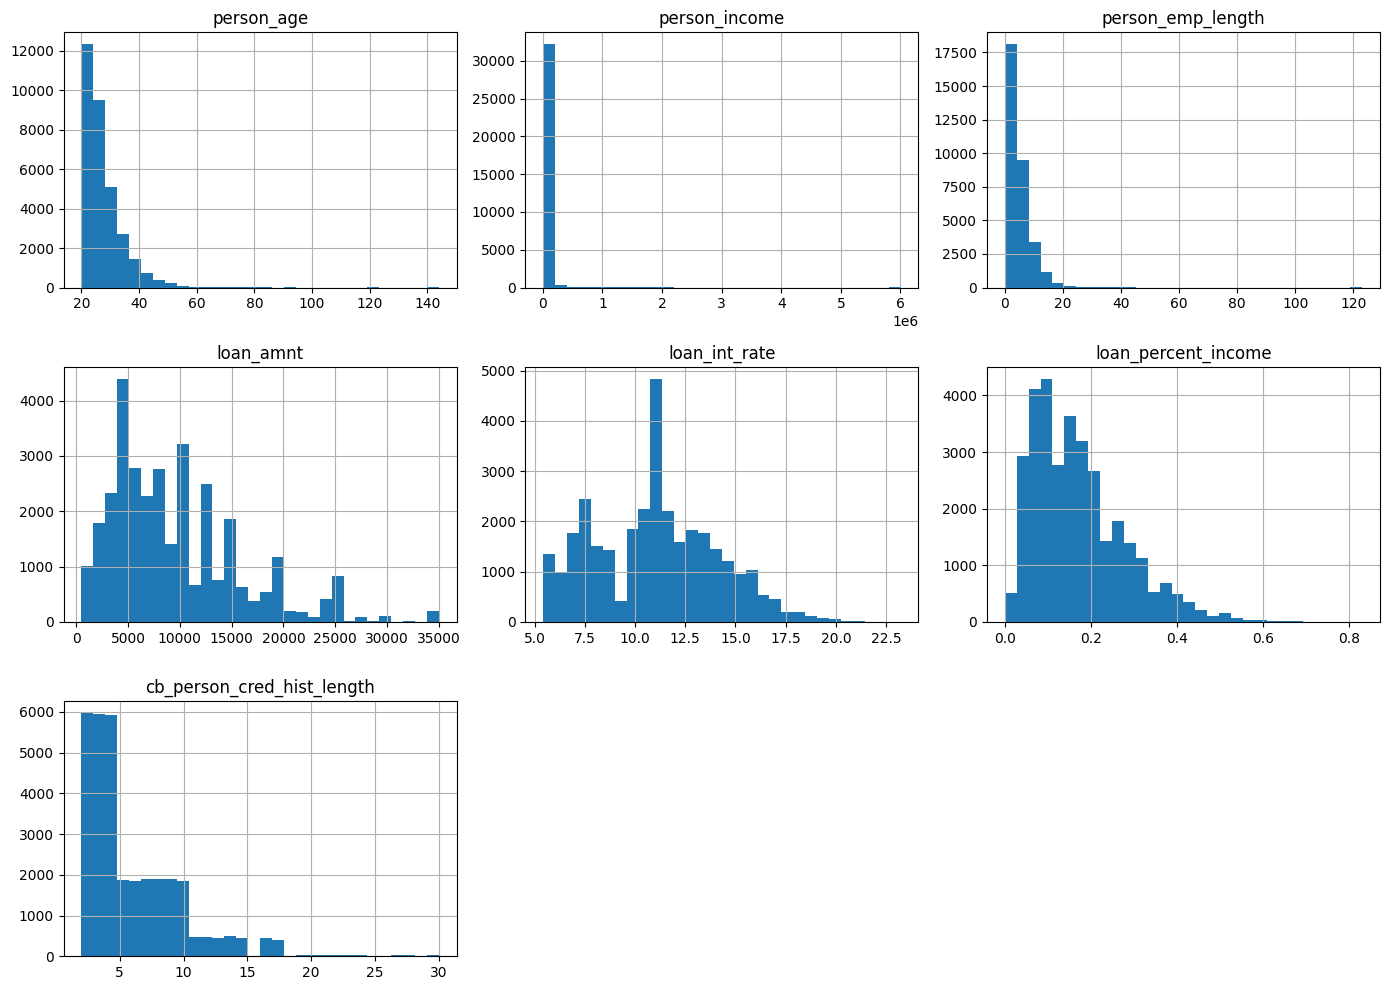

In [29]:

import matplotlib.pyplot as plt

# Числові ознаки без цільової змінної
numeric_df = df.select_dtypes(include='number').drop(columns='loan_status')

# Гістограми
numeric_df.hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()



### Висновок

Аналіз описової статистики та гістограм показав, що більшість числових змінних мають правосторонню асиметрію, а деякі містять значні викиди.

**Основні результати:**

- Вік позичальників (`person_age`)  медіана 26 років, більшість позичальників молодого віку.
- Річний дохід (`person_income`)  медіана 55 000, спостерігається сильна правостороння асиметрія.
- Стаж роботи (`person_emp_length`)  медіана 4 роки, переважає невеликий стаж.
- Сума кредиту (`loan_amnt`)  медіана 8 000, частіше зустрічаються кредити невеликих сум.
- Відсоткова ставка (`loan_int_rate`)  медіана 10,99%, найбільша концентрація значень у межах приблизно 7 - 15%.
- Кредитне навантаження (`loan_percent_income`) медіана 15% річного доходу, розподіл зміщений вправо.
- Тривалість кредитної історії (`cb_person_cred_hist_length`)  медіана 4 роки, переважають короткі кредитні історії.

**Виявлені аномалії:**

- `person_age`  максимальний вік 144 роки.
- `person_emp_length`  максимальний стаж 123 роки.
- `person_income`  максимальний дохід 6 000 000, що значно перевищує медіану.

Числові змінні мають різні розподіли та масштаби. Найбільш помітні викиди спостерігаються у віці, стажу роботи та доходах позичальників. Під час подальшої підготовки даних необхідно врахувати ці аномалії, а також застосувати масштабування ознак для навчання моделі логістичної регресії.


**2.3 Пошук та обробка викидів методом IQR**



Використаємо міжквартильний розмах (IQR) для визначення викидів у колонці `person_income`.

Формула:

$$
IQR = Q3 - Q1
$$

Межі викидів:

- Нижня: $Q1 - 1.5 \times IQR$
- Верхня: $Q3 + 1.5 \times IQR$

У цьому завданні обробимо викиди шляхом видалення рядків, які виходять за визначені межі.


In [30]:
#  Розрахунок квартилів та IQR
Q1 = df['person_income'].quantile(0.25)
Q3 = df['person_income'].quantile(0.75)
IQR = Q3 - Q1

#  Межі викидів
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

#  Кількість викидів
outliers = df[(df['person_income'] < lower) | (df['person_income'] > upper)]
print("Кількість викидів:", len(outliers))

#  Видалення викидів
df = df[(df['person_income'] >= lower) & (df['person_income'] <= upper)].copy()

print("Розмір датасету після очищення:", df.shape)


Кількість викидів: 1484
Розмір датасету після очищення: (31097, 12)


In [31]:
# Таблиця результатів IQR
result = pd.DataFrame({
    'Показник': ['Q1 (25%)', 'Q3 (75%)', 'IQR', 'Нижня межа',
                 'Верхня межа', 'Кількість викидів', 'Рядків після очищення'],
    'Значення': [Q1, Q3, IQR, lower, upper, len(outliers), len(df)]
})

display(result.set_index('Показник').round(0))


,Значення
Показник,
Q1 (25%),38500.0
Q3 (75%),79200.0
IQR,40700.0
Нижня межа,-22550.0
Верхня межа,140250.0
Кількість викидів,1484.0
Рядків після очищення,31097.0



### Висновок

Для виявлення викидів у колонці річного доходу (`person_income`) застосовано метод міжквартильного розмаху (IQR).

**Основні результати:**
- Перший квартиль (Q1)  38 500.
- Третій квартиль (Q3)  79 200.
- Міжквартильний розмах (IQR)  40 700.
- Нижня межа  −22 550.
- Верхня межа  140 250.
- Виявлено та видалено 1 484 викиди (4,55%).
- Після очищення залишилося 31 097 спостережень.

 Метод IQR дозволив виявити та видалити аномально високі значення доходу (`person_income`), які перевищували верхню межу 140 250. Кількість спостережень зменшилася з 32 581 до 31 097.




**Завдання 2.4  Аналіз категоріальних змінних відносно цільової**


Проаналізуємо 4 категоріальні змінні та визначимо, як вони пов'язані з дефолтом (loan_status = 1).Для кожної категорії розрахуємо кількість записів, частоту зустрічання (%) та частку дефолтів (%).

In [32]:

# Аналіз категоріальних змінних
cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    print(f"\n{col}")

    result = df.groupby(col)['loan_status'].agg(['count', 'mean'])
    result.columns = ['Кількість', 'Частка дефолтів, %']

    result['Частота, %'] = result['Кількість'] / len(df) * 100
    result['Частка дефолтів, %'] *= 100

    display(result.round(2).sort_values('Кількість', ascending=False))



person_home_ownership


,Кількість,"Частка дефолтів, %","Частота, %"
person_home_ownership,,,
RENT,16102,31.95,51.78
MORTGAGE,12426,12.84,39.96
OWN,2469,7.78,7.94
OTHER,100,32.00,0.32



loan_intent


,Кількість,"Частка дефолтів, %","Частота, %"
loan_intent,,,
EDUCATION,6201,17.61,19.94
MEDICAL,5846,27.15,18.80
VENTURE,5445,15.37,17.51
PERSONAL,5260,20.61,16.91
DEBTCONSOLIDATION,4955,29.08,15.93
HOMEIMPROVEMENT,3390,27.20,10.90



loan_grade


,Кількість,"Частка дефолтів, %","Частота, %"
loan_grade,,,
A,10343,10.34,33.26
B,9924,16.90,31.91
C,6191,21.50,19.91
D,3459,60.08,11.12
E,899,65.63,2.89
F,221,71.95,0.71
G,60,98.33,0.19



cb_person_default_on_file


,Кількість,"Частка дефолтів, %","Частота, %"
cb_person_default_on_file,,,
N,25626,18.93,82.41
Y,5471,38.59,17.59


Аналіз категоріальних змінних показав, що частка дефолтів суттєво відрізняється залежно від кредитного рейтингу, типу житла, мети кредиту та історії попередніх дефолтів. Найбільша частка дефолтів спостерігається серед позичальників із низьким кредитним рейтингом і попередніми дефолтами. Отже, ці ознаки потенційно корисні для прогнозування кредитного ризику.

**2.5 Візуалізація взаємозв'язку ознак із цільовою змінною**

Побудуємо два типи графіків:
1. Boxplot - порівняємо розподіл числових ознак для позичальників із дефолтом і без дефолту.
2. Стовпчикові діаграми - покажемо частку дефолтів для кожної категоріальної ознаки.

###Числові ознаки Boxplot

На графіках порівняємо значення ознак для двох класів: 0 - без дефолту, 1 - дефолт.

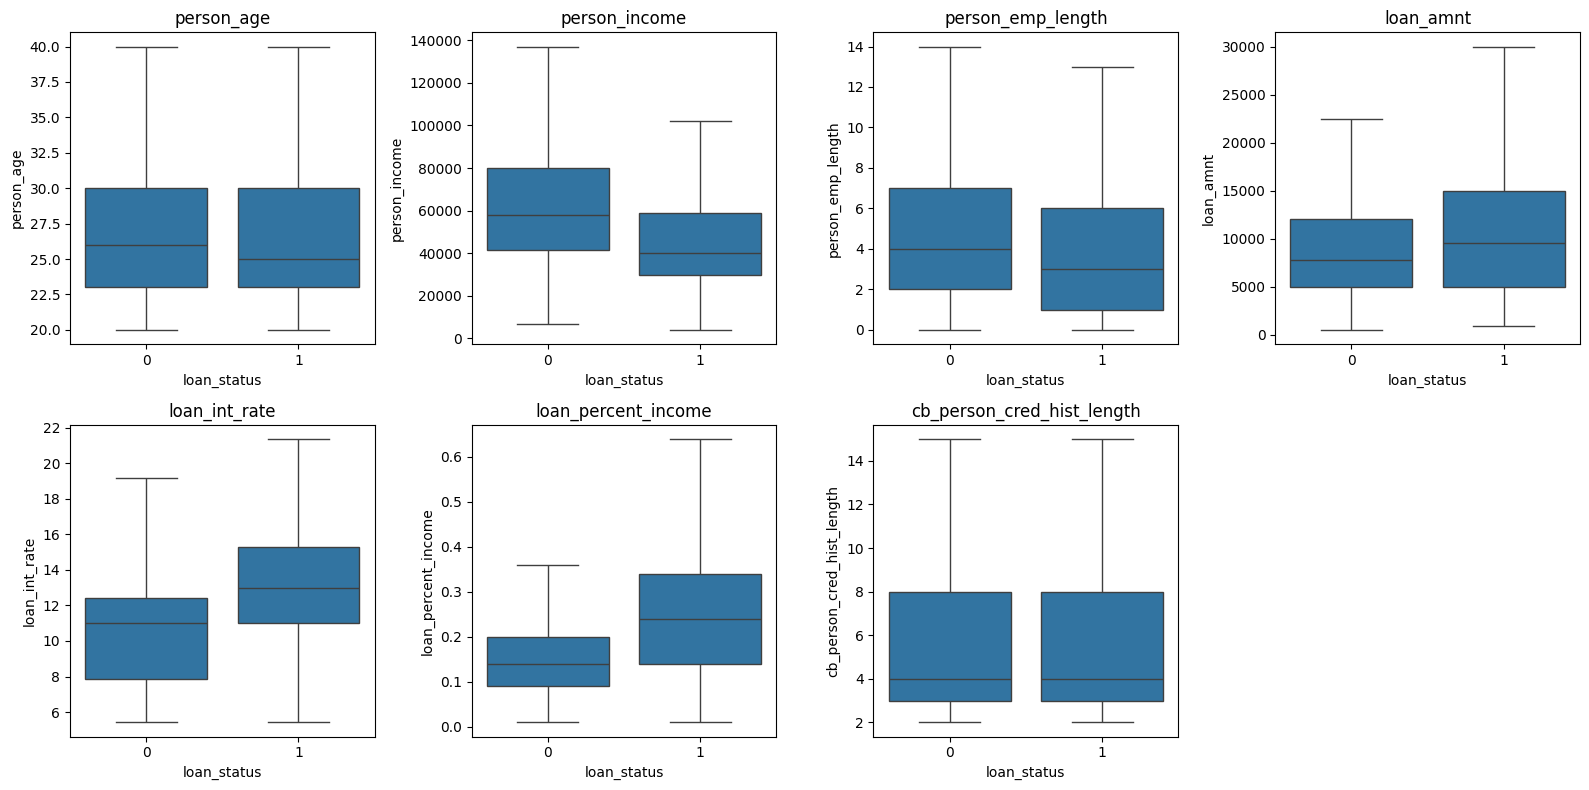

In [33]:

import seaborn as sns
import matplotlib.pyplot as plt

# Числові ознаки
num_cols = df.select_dtypes(include='number').columns.drop('loan_status')

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(data=df, x='loan_status', y=col, ax=ax, showfliers=False)
    ax.set_title(col)

fig.delaxes(axes.flat[-1])
plt.tight_layout()
plt.show()


### Категоріальні ознаки - частка дефолтів

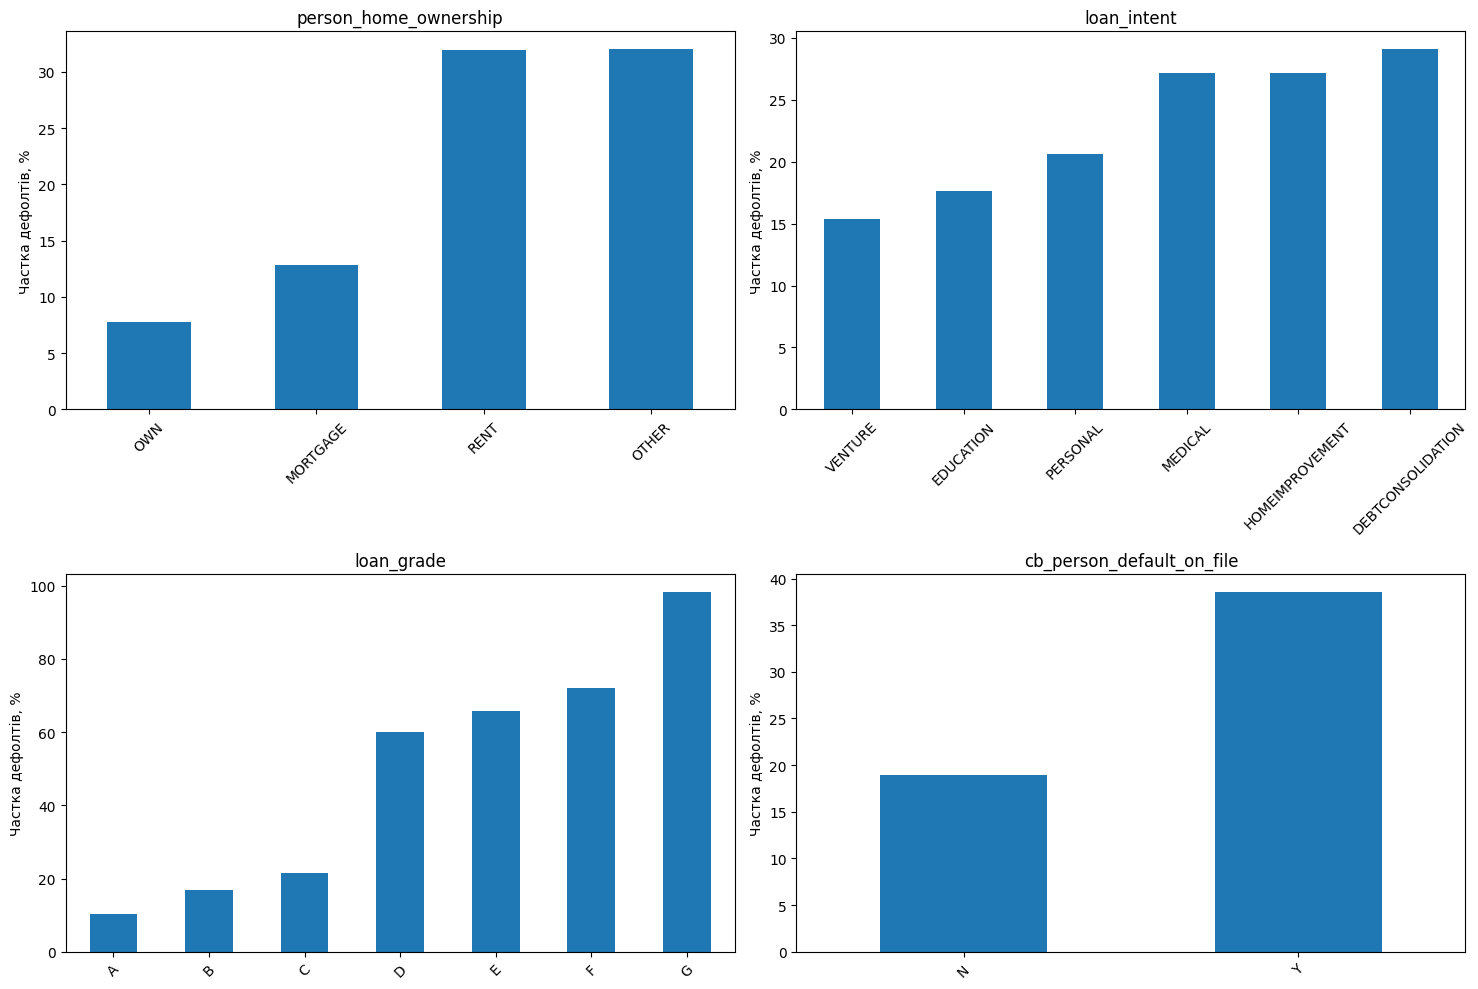

In [34]:

# Категоріальні ознаки
cat_cols = df.select_dtypes(include='object').columns

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, col in zip(axes.flat, cat_cols):
    default_rate = df.groupby(col)['loan_status'].mean() * 100
    default_rate.sort_values().plot(kind='bar', ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel('Частка дефолтів, %')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


Візуалізація показала, що кредитний рейтинг (`loan_grade`), відсоткова ставка (`loan_int_rate`), кредитне навантаження (`loan_percent_income`) та історія попередніх дефолтів суттєво пов'язані з ризиком неповернення кредиту. Найвища частка дефолтів спостерігається серед позичальників із низьким кредитним рейтингом, високими відсотковими ставками та попередніми дефолтами. Ці ознаки доцільно використовувати для побудови моделі класифікації.


---

## Завдання 3: Аналіз кореляцій та Feature Engineering (3 бали)

**Що потрібно зробити:**
1. Побудуйте матрицю кореляцій для числових змінних.
2. Закодуйте категоріальні змінні.
3. Виберіть фінальний набір ознак, можна лишити всі, якщо ви вважаєте, що це - доцільно.



**3.1 Матриця кореляцій числових змінних**

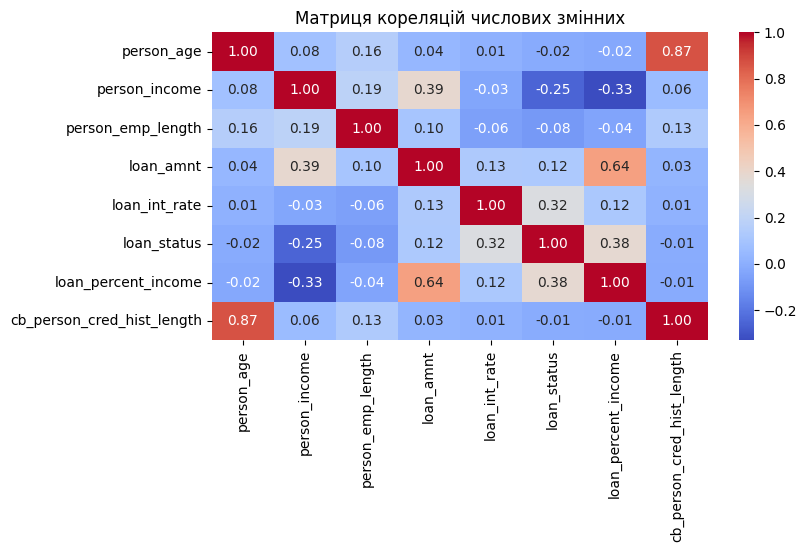

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt

# Матриця кореляцій числових змінних
corr_matrix = df.select_dtypes(include='number').corr()

# Теплова карта кореляцій
plt.figure(figsize=(8, 4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Матриця кореляцій числових змінних')
plt.show()



### Висновок

Кореляційний аналіз показав такі взаємозв'язки з цільовою змінною (`loan_status`):

**1. Кореляція з цільовою змінною:**

- Кредитне навантаження (`loan_percent_income`)  r = 0,38, найбільший позитивний зв'язок із дефолтом.
- Відсоткова ставка (`loan_int_rate`)  r = 0,32, помірний позитивний зв'язок.
- Річний дохід (`person_income`)  r = −0,25, слабкий негативний зв'язок.
- Сума кредиту (`loan_amnt`)  r = 0,12, слабкий позитивний зв'язок.

**2. Кореляція між ознаками:**

- Вік позичальника (`person_age`) та тривалість кредитної історії (`cb_person_cred_hist_length`)  r = 0,87, сильна позитивна кореляція, що може свідчити про сильний взаємозв’язок між цими ознаками.
- Сума кредиту (`loan_amnt`) та кредитне навантаження (`loan_percent_income`)  r = 0,64, помірно сильна позитивна кореляція.

Найбільш помітний позитивний лінійний зв'язок із ризиком дефолту мають кредитне навантаження та відсоткова ставка. Річний дохід має негативну кореляцію з дефолтом, тобто вищі доходи пов'язані з нижчою частотою дефолтів.
Виявлену сильну кореляцію між віком позичальника та тривалістю кредитної історії необхідно врахувати під час побудови моделі логістичної регресії.
Кореляція характеризує статистичний зв'язок між змінними, але не доводить причинно-наслідкової залежності.


**3.2 Кодування категоріальних змінних**

In [36]:
# Вибираємо категоріальні колонки
cat_cols = df.select_dtypes(include='object').columns.tolist()

# Кодуємо категоріальні змінні
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

# Перевіряємо результат
print("Розмір датасету:", df_encoded.shape)
display(df_encoded.head())


Розмір датасету: (31097, 23)


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length,person_home_ownership_OTHER,person_home_ownership_OWN,...,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,loan_grade_B,loan_grade_C,loan_grade_D,loan_grade_E,loan_grade_F,loan_grade_G,cb_person_default_on_file_Y
0,22,59000,123.0,35000,16.02,1,0.59,3,0,0,...,0,1,0,0,0,1,0,0,0,1
1,21,9600,5.0,1000,11.14,0,0.10,2,0,1,...,0,0,0,1,0,0,0,0,0,0
2,25,9600,1.0,5500,12.87,1,0.57,3,0,0,...,1,0,0,0,1,0,0,0,0,0
3,23,65500,4.0,35000,15.23,1,0.53,2,0,0,...,1,0,0,0,1,0,0,0,0,0
4,24,54400,8.0,35000,14.27,1,0.55,4,0,0,...,1,0,0,0,1,0,0,0,0,1



### Висновок

Категоріальні змінні перетворено на числові за допомогою методу One-Hot Encoding (`pd.get_dummies()`).
Після кодування датасет містить 31 097 спостережень та 23 стовпці, з яких 22  ознаки для навчання моделі, а `loan_status` - цільова змінна.
Параметр `drop_first=True` дозволив уникнути створення зайвих бінарних стовпців.

Категоріальні ознаки успішно закодовано, кількість спостережень залишилася незмінною. Дані підготовлено до подальшого вибору ознак і навчання моделі логістичної регресії.


**3.3 Вибір фінального набору ознак**

In [37]:

# Вибираємо всі ознаки, крім цільової
X = df_encoded.drop(columns='loan_status')

# Цільова змінна
y = df_encoded['loan_status']

# Перевірка
print("Кількість ознак:", X.shape[1])
print("Розмір X:", X.shape)
print("Розмір y:", y.shape)


Кількість ознак: 22
Розмір X: (31097, 22)
Розмір y: (31097,)


###Висновок
Для побудови моделі логістичної регресії обрано всі 22 ознаки після кодування категоріальних змінних. Незважаючи на високу кореляцію між віком позичальника та тривалістю кредитної історії (r = 0,86) вирішено залишити обидві ознаки для початкової моделі.


---

## Завдання 4: Підготовка даних та навчання моделі (3 бали)

**Що потрібно зробити:**
1. Розділіть дані на X та y
2. Поділіть на навчальну та тестову вибірки
3. Застосуйте масштабування
4. Навчіть модель логістичної регресії
5. Зробіть прогнози на тренувальній та тестовій вибірках.



**4.1 Розділення даних на X та y**

In [38]:

# Ознаки для навчання моделі
X = df_encoded.drop(columns='loan_status')

# Цільова змінна
y = df_encoded['loan_status']

# Перевірка розмірів
print("Розмір X:", X.shape)
print("Розмір y:", y.shape)


Розмір X: (31097, 22)
Розмір y: (31097,)



###Висновок
Дані розділено на 22 незалежні ознаки (`X`) та цільову змінну (`y`)  статус кредиту (`loan_status`). Для подальшого навчання моделі підготовлено 31 097 спостережень.


**4.2 Поділ на навчальну та тестову вибірки**

In [39]:
from sklearn.model_selection import train_test_split

# Поділ даних на навчальну та тестову вибірки
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Перевірка розмірів вибірок
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (24877, 22)
X_test: (6220, 22)
y_train: (24877,)
y_test: (6220,)


###Висновок
Дані успішно розділено на навчальну (80%) та тестову (20%) вибірки зі збереженням пропорцій класів цільової змінної (loan_status).

**4.3 Масштабування даних**

In [40]:
from sklearn.preprocessing import StandardScaler

# Створюємо об'єкт масштабування
scaler = StandardScaler()

# Масштабуємо навчальну вибірку
X_train_scaled = scaler.fit_transform(X_train)

# Масштабуємо тестову вибірку
X_test_scaled = scaler.transform(X_test)

# Перевіряємо розміри
print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)


X_train_scaled: (24877, 22)
X_test_scaled: (6220, 22)


###Висновок
Масштабування ознак виконано методом StandardScaler. Параметри стандартизації розраховано на навчальній вибірці та застосовано до тестової, що запобігає витоку інформації на етапі масштабування. Дані підготовлено до навчання моделі логістичної регресії.

**4.4 Навчання моделі логістичної регресії**

In [41]:
from sklearn.linear_model import LogisticRegression

# Створюємо модель логістичної регресії
model = LogisticRegression(random_state=42, max_iter=1000)

# Навчаємо модель на навчальній вибірці
model.fit(X_train_scaled, y_train)

print("Модель логістичної регресії навчена!")


Модель логістичної регресії навчена!


In [42]:
model

LogisticRegression(max_iter=1000, random_state=42)

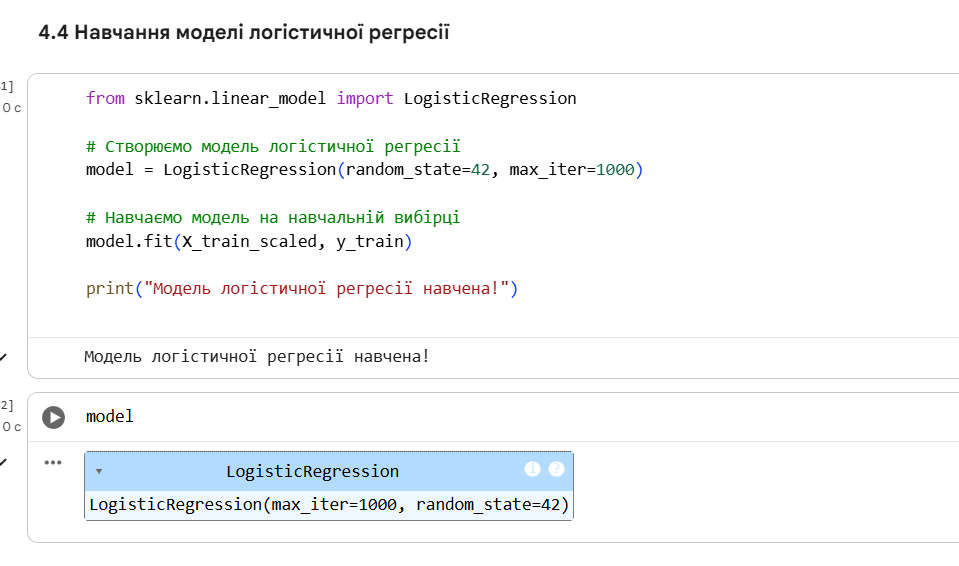


### Висновок

Модель логістичної регресії (`LogisticRegression`) успішно навчено на масштабованій навчальній вибірці яка містить 24 877 спостережень та 22 ознаки.
Навчання завершилося без помилок. Модель готова до прогнозування кредитного ризику та подальшого оцінювання якості класифікації.


**4.5 Прогнозування на навчальній та тестовій вибірках**

In [43]:
# Прогнози на навчальній вибірці
y_train_pred = model.predict(X_train_scaled)

# Прогнози на тестовій вибірці
y_test_pred = model.predict(X_test_scaled)

# Перевірка результатів
print("Кількість прогнозів (train):", len(y_train_pred))
print("Кількість прогнозів (test):", len(y_test_pred))

print("\nПерші 10 прогнозів (train):", y_train_pred[:10])
print("Перші 10 прогнозів (test):", y_test_pred[:10])


Кількість прогнозів (train): 24877
Кількість прогнозів (test): 6220

Перші 10 прогнозів (train): [0 0 0 1 0 0 0 0 1 0]
Перші 10 прогнозів (test): [0 0 0 0 1 0 0 0 0 0]


###Висновок
Модель логістичної регресії успішно сформувала прогнози для навчальної (24 877 спостережень) та тестової (6 220 спостережень) вибірок. Прогнозовані значення loan_status належать до двох класів: 0 — без дефолту, 1 — дефолт.


---

## Завдання 5: Оцінка якості моделі (4 бали)

**Що потрібно зробити:**
1. Побудуйте confusion matrix.
2. Обчисліть основні метрики (accuracy, precision, recall, f1).
3. Побудуйте ROC-криву та обчисліть AUC
4. Проаналізуйте важливість ознак.
5. Зробіть висновки про якість моделі та які ознаки найбільше впливають на прогноз.


**5.1 Побудова матриці помилок (Confusion Matrix)**

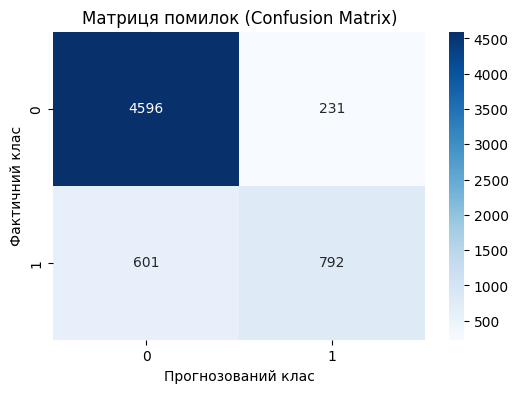

In [44]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Матриця помилок на тестовій вибірці
cm = confusion_matrix(y_test, y_test_pred)

# Візуалізація
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Прогнозований клас')
plt.ylabel('Фактичний клас')
plt.title('Матриця помилок (Confusion Matrix)')
plt.show()


Матриця помилок побудована коректно. За результатами оцінювання моделі логістичної регресії отримано такі показники:

| Показник | Кількість | Пояснення |
|---|---:|---|
| TN (True Negative) | 4 596 | Правильно визначено відсутність дефолту |
| FP (False Positive) | 231 | Помилково спрогнозовано дефолт |
| FN (False Negative) | 601 | Модель не виявила фактичний дефолт |
| TP (True Positive) | 792 | Правильно визначено дефолт |
| Разом | 6 220 | Загальна кількість спостережень тестової вибірки |

**Основні результати:**
- Accuracy — 86,62% правильних прогнозів.
- Recall — 56,86% фактичних дефолтів виявлено.
- 601 дефолт (FN) модель помилково класифікувала як відсутність дефолту.

Модель правильно класифікувала 5 388 із 6 220 спостережень (86,62%). Водночас вона не виявила 601 фактичний дефолт, що свідчить про недостатню чутливість до ризикових позичальників. Для прогнозування кредитного ризику важливо підвищити показник Recall, щоб зменшити кількість пропущених дефолтів.

**5.2 Обчислення основних метрик моделі**

In [45]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Обчислення основних метрик
print(f"Accuracy:  {accuracy_score(y_test, y_test_pred) * 100:.2f}%")
print(f"Precision: {precision_score(y_test, y_test_pred) * 100:.2f}%")
print(f"Recall:    {recall_score(y_test, y_test_pred) * 100:.2f}%")
print(f"F1-score:  {f1_score(y_test, y_test_pred) * 100:.2f}%")


Accuracy:  86.62%
Precision: 77.42%
Recall:    56.86%
F1-score:  65.56%


###Висновок
Модель логістичної регресії показала загальну точність класифікації (Accuracy) 86,62%. Точність прогнозування дефолтів (Precision) становить 77,42%, однак повнота їх виявлення (Recall) - лише 56,86%. Значення F1-score становить 65,56%.

Отже, модель демонструє хорошу загальну точність, проте пропускає значну частину фактичних дефолтів. Для задачі кредитного ризику доцільно підвищувати Recall, враховуючи можливе зростання кількості хибних спрацювань.

**5.3  Побудова ROC-кривої та обчислення AUC**

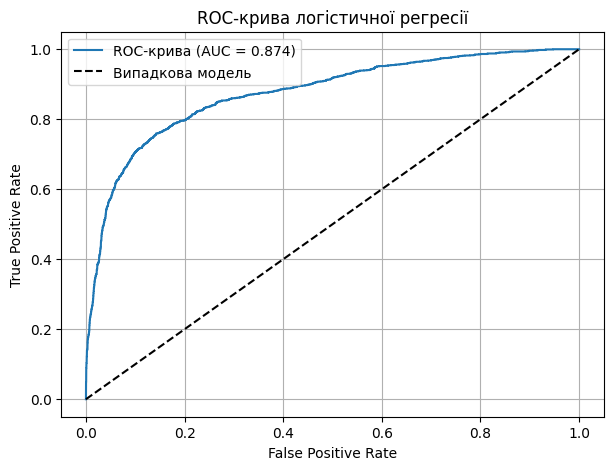

ROC-AUC: 0.8743


In [46]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Ймовірність дефолту на тестовій вибірці
y_test_proba = model.predict_proba(X_test_scaled)[:, 1]

# Розрахунок ROC-кривої та AUC
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
auc_score = roc_auc_score(y_test, y_test_proba)

# Побудова ROC-кривої
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'ROC-крива (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Випадкова модель')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-крива логістичної регресії')
plt.legend()
plt.grid(True)
plt.show()

# Результат AUC
print(f"ROC-AUC: {auc_score:.4f}")



### Висновок

Побудована ROC-крива показала хорошу здатність моделі логістичної регресії розрізняти позичальників із дефолтом (`loan_status = 1`) та без дефолту (`loan_status = 0`).

Значення ROC-AUC = 0,8743 свідчить про хорошу здатність моделі розділяти класи порівняно з випадковою моделлю (AUC = 0,5).
Модель добре розрізняє ризикових і надійних позичальників, проте для підвищення повноти виявлення дефолтів (Recall) доцільно розглянути зміну порогу класифікації.


**5.4 Аналіз важливості ознак (Feature Importance)**

,Коефіцієнт
loan_percent_income,1.319
loan_grade_D,0.813
loan_amnt,-0.546
loan_grade_E,0.478
person_home_ownership_OWN,-0.459
person_home_ownership_RENT,0.404
loan_intent_VENTURE,-0.400
loan_intent_EDUCATION,-0.327
loan_grade_G,0.310
loan_grade_F,0.269


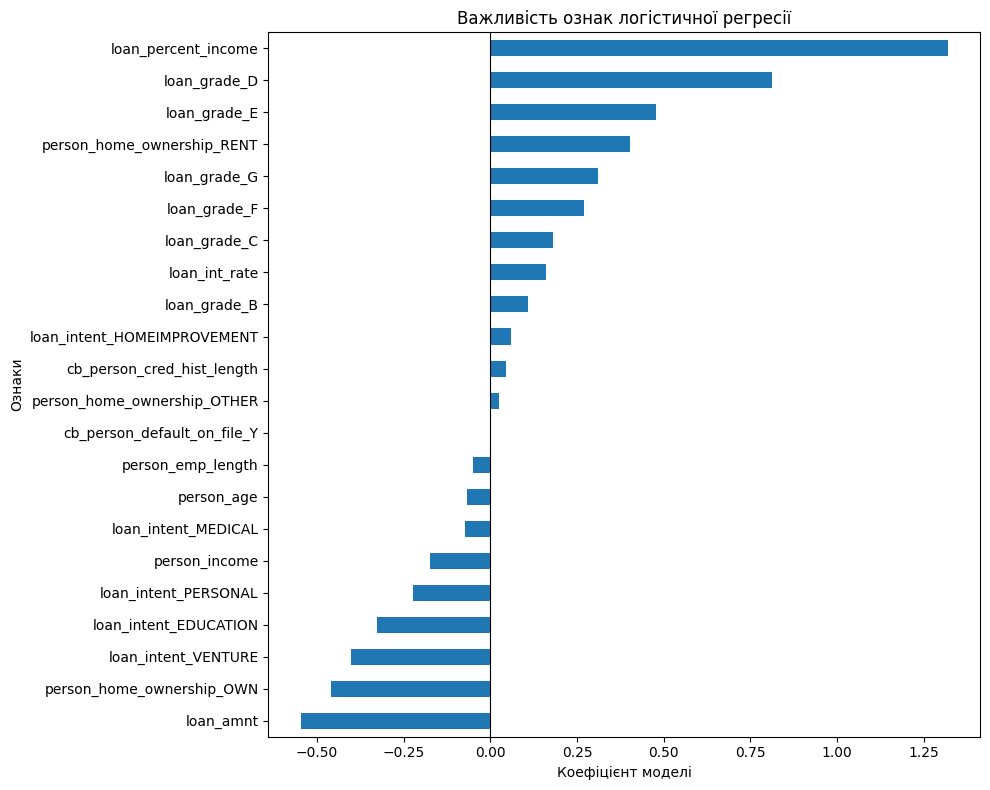

In [47]:
# Коефіцієнти логістичної регресії
importance = pd.Series(model.coef_[0], index=X.columns)

# Сортування за абсолютною величиною коефіцієнтів
importance = importance.reindex(
    importance.abs().sort_values(ascending=False).index
)

# Таблиця важливості ознак
display(importance.to_frame('Коефіцієнт').round(3))

# Графік важливості ознак
plt.figure(figsize=(10, 8))
importance.sort_values().plot(kind='barh')

plt.title('Важливість ознак логістичної регресії')
plt.xlabel('Коефіцієнт моделі')
plt.ylabel('Ознаки')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()



### Висновок

Аналіз коефіцієнтів логістичної регресії показав, що найбільш позитивні коефіцієнти мають:

- Кредитне навантаження (`loan_percent_income`)  +1,319.
- Кредитний рейтинг D** (`loan_grade_D`)  +0,813.
- Кредитний рейтинг E** (`loan_grade_E`)  +0,478.
- Оренда житла** (`person_home_ownership_RENT`)  +0,404.

Найбільші від'ємні коефіцієнти мають:

- Сума кредиту** (`loan_amnt`)  −0,546.
- Власне житло** (`person_home_ownership_OWN`)  −0,459.
- Мета кредиту — бізнес** (`loan_intent_VENTURE`)  −0,400.

Кредитне навантаження та кредитний рейтинг є одними з найважливіших ознак моделі. Додатні коефіцієнти пов'язані зі збільшенням прогнозованих шансів дефолту, а від'ємні - зі зменшенням.
Ці зв'язки оцінюються з урахуванням інших ознак моделі та не доводять причинно-наслідкової залежності.


**5.5 Висновки про якість моделі та важливість ознак**

**1. Оцінка якості моделі**

Модель логістичної регресії продемонструвала хорошу загальну якість прогнозування кредитного ризику:

- **Accuracy — 86,62%** — частка правильних прогнозів.
- **Precision — 77,42%** — точність прогнозування дефолтів.
- **Recall — 56,86%** — частка виявлених фактичних дефолтів.
- **F1-score — 65,56%** — баланс між Precision та Recall.
- **ROC-AUC — 0,8743** — хороша здатність моделі розрізняти класи.

За результатами матриці помилок модель правильно класифікувала **5 388 із 6 220 спостережень**, проте не виявила **601 фактичний дефолт (FN)**. Це свідчить про необхідність підвищення Recall.

**2. Найважливіші ознаки моделі**

Аналіз коефіцієнтів логістичної регресії показав, що найбільший вплив на прогноз мають:

- **Кредитне навантаження** (`loan_percent_income`, +1,319) — найсильніший позитивний коефіцієнт.
- **Кредитний рейтинг D** (`loan_grade_D`, +0,813) — підвищує прогнозовані шанси дефолту.
- **Сума кредиту** (`loan_amnt`, −0,546) — від'ємний умовний зв'язок із дефолтом.
- **Кредитний рейтинг E** (`loan_grade_E`, +0,478) — позитивний зв'язок із дефолтом.
- **Власне житло** (`person_home_ownership_OWN`, −0,459) — пов'язане зі зниженням прогнозованих шансів дефолту.
- **Оренда житла** (`person_home_ownership_RENT`, +0,404) — пов'язана з підвищенням прогнозованих шансів дефолту.

Коефіцієнти характеризують вплив ознак на логарифм шансів дефолту за інших рівних умов, а не прямий причинно-наслідковий вплив.

### Висновок

Побудована модель логістичної регресії демонструє хорошу здатність розрізняти ризикових і надійних позичальників. Найбільше значення для прогнозування мають кредитне навантаження (`loan_percent_income`) та кредитний рейтинг (`loan_grade`).

Водночас модель пропускає значну частину фактичних дефолтів. Для покращення результатів доцільно розглянути зміну порогу класифікації та врахування дисбалансу класів, щоб підвищити Recall без надмірного збільшення кількості хибних спрацювань.


---

## Завдання 6: Оптимізація порогу та бізнес-аналіз (2 бали)

**Що потрібно зробити:**
1. Проаналізуйте метрики precision, recall, F1 при різних порогах класифікації (мінімум - 5 різних порогів). Візуалізуйте як змінюються метрики якості при зміні порогу.
2. Оберіть оптимальний поріг для бізнес-задачі - можна обрати виходячи з попереднього пункту, або додати своїх роздумів і обрати інший.



**6.1 Аналіз метрик при різних порогах класифікації**

Перевіримо, як змінюються Precision, Recall та F1-score при зміні порогу класифікації.
Використаємо 6 порогів: 0.2, 0.3, 0.4, 0.5, 0.6, 0.7.

,Поріг,Precision,Recall,F1-score
0,0.2,53.04,80.11,63.83
1,0.3,62.78,73.51,67.72
2,0.4,71.06,65.76,68.31
3,0.5,77.42,56.86,65.56
4,0.6,80.96,47.02,59.49
5,0.7,83.11,35.68,49.92


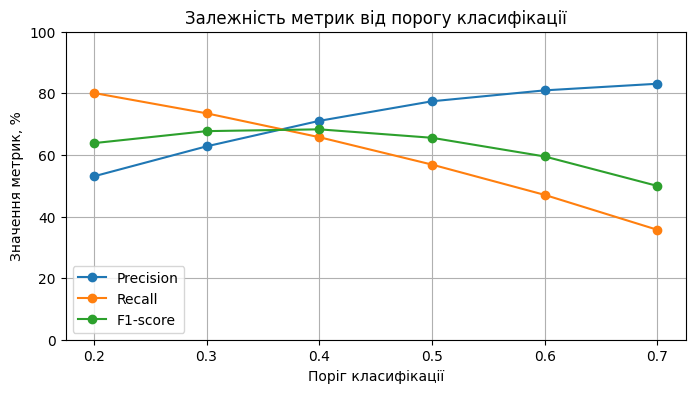

In [52]:
# Пороги класифікації
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

results = []

# Розрахунок метрик для кожного порогу
for threshold in thresholds:
    y_pred = (y_test_proba >= threshold).astype(int)

    results.append({
        'Поріг': threshold,
        'Precision': precision_score(y_test, y_pred) * 100,
        'Recall': recall_score(y_test, y_pred) * 100,
        'F1-score': f1_score(y_test, y_pred) * 100})

# Таблиця результатів
metrics_df = pd.DataFrame(results)
display(metrics_df.round(2))

# Візуалізація метрик
metrics_df.plot(
    x='Поріг',
    y=['Precision', 'Recall', 'F1-score'],
    marker='o',
    figsize=(8, 4))

plt.title('Залежність метрик від порогу класифікації')
plt.xlabel('Поріг класифікації')
plt.ylabel('Значення метрик, %')
plt.ylim(0, 100)
plt.grid(True)
plt.show()


###Висновок
Аналіз показав, що зі збільшенням порогу класифікації Precision зростає, а Recall знижується. Найкращий баланс між цими метриками серед перевірених порогів досягнуто при 0,4 (F1-score = 68,31%).

Порівняно зі стандартним порогом 0,5, зниження порогу до 0,4 підвищує Recall із 56,86% до 65,76%, що дозволяє виявляти більше фактичних дефолтів.

Для нашої моделі доцільно розглянути поріг 0,4, оскільки він забезпечує найвище значення F1-score серед досліджених варіантів. Якщо головним пріоритетом є максимальне виявлення ризикових позичальників, можна розглянути нижчий поріг, враховуючи зростання кількості хибних спрацювань.

**6.2 Вибір оптимального порогу класифікації**

Для нашої бізнес-задачі пропоную обрати **поріг 0,4**, оскільки він забезпечує найкращий баланс між Precision та Recall серед перевірених варіантів.

### 1. Порівняння зі стандартним порогом

| Метрика | Поріг 0,5 | Поріг 0,4 |
|---|---:|---:|
| Precision | 77,42% | 71,06% |
| Recall | 56,86% | 65,76% |
| F1-score | 65,56% | 68,31% |

При зниженні порогу з 0,5 до 0,4:

- Recall збільшується на 8,90 відсоткового пункту.
- F1-score збільшується на 2,75 відсоткового пункту.
- Precision знижується на 6,36 відсоткового пункту.

Для банку це означає, що модель зможе виявляти більше потенційних дефолтів, хоча частіше помилково позначатиме надійних позичальників як ризикових.


In [49]:
# Обраний поріг класифікації
best_threshold = 0.4

# Прогнози з новим порогом
y_pred_optimal = (y_test_proba >= best_threshold).astype(int)

# Оцінка метрик
print(f"Обраний поріг: {best_threshold}")
print(f"Precision: {precision_score(y_test, y_pred_optimal) * 100:.2f}%")
print(f"Recall: {recall_score(y_test, y_pred_optimal) * 100:.2f}%")
print(f"F1-score: {f1_score(y_test, y_pred_optimal) * 100:.2f}%")


Обраний поріг: 0.4
Precision: 71.06%
Recall: 65.76%
F1-score: 68.31%



### Висновок

Для прогнозування кредитного ризику обрано поріг класифікації 0,4, який забезпечує найвищий F1-score (68,31%) серед перевірених варіантів.

Порівняно зі стандартним порогом 0,5, показник Recall зріс із 56,86% до 65,76%, а Precision знизився з 77,42% до 71,06%.

Поріг 0,4 дозволяє банку виявляти більше потенційно ризикових позичальників і зменшувати кількість пропущених дефолтів. Це важливо, тому що невиявлений дефолт може призвести до фінансових втрат.

Тобто поріг 0,4 є доцільним вибором для нашої навчальної моделі. Для практичного застосування в банку його потрібно додатково перевірити з урахуванням вартості помилок класифікації.



---

## Завдання 7 (Опціональне): Покращення моделі та висновки (2 бали)

**Що потрібно зробити:**

На цих же даних навчіть DecisionTreeClassifier та RandomForestClassifier. Яка з трьох моделей дає найкращий результат на тестовому наборі?

Поріг класифікації можна для порівняння якостей моделей використовувати стандартний 0.5, або той, що ви виявили, як оптимальний на попередньому кроці.


**7. Покращення моделі та порівняння результатів**

Порівняємо три моделі класифікації:

1. Logistic Regression - навчена модель.
2. Decision Tree - дерево рішень.
3. Random Forest - випадковий ліс.

Для коректного порівняння використаємо однакові навчальну й тестову вибірки та стандартний поріг 0,5 для всіх трьох моделей.


In [50]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Навчання дерева рішень
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

# Навчання випадкового лісу
forest = RandomForestClassifier(n_estimators=100, random_state=42)
forest.fit(X_train, y_train)

# Прогнози трьох моделей
pred_log = model.predict(X_test_scaled)
pred_tree = tree.predict(X_test)
pred_forest = forest.predict(X_test)

# Порівняння метрик
results = []

for name, pred in zip(
    ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    [pred_log, pred_tree, pred_forest]
):
    results.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, pred) * 100,
        'Precision': precision_score(y_test, pred) * 100,
        'Recall': recall_score(y_test, pred) * 100,
        'F1-score': f1_score(y_test, pred) * 100
    })

# Таблиця результатів
comparison_df = pd.DataFrame(results)
display(comparison_df.round(2))


,Модель,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,86.62,77.42,56.86,65.56
1,Decision Tree,89.16,75.44,76.53,75.98
2,Random Forest,92.88,95.76,71.36,81.78



### Аналіз

- **Random Forest**  найкраща модель за Accuracy, Precision та F1-score.
- **Decision Tree**  найкраще виявляє фактичні дефолти (Recall = 76,53%).
- **Logistic Regression**  поступається двом іншим моделям за F1-score та Recall.

### Висновок

**Random Forest показала найкращий загальний результат** серед трьох моделей: Accuracy = 92,88%, Precision = 95,76%, F1-score = 81,78%.

Водночас Decision Tree має найвищий Recall (76,53%), тому для банківської задачі, де важливо мінімізувати кількість пропущених дефолтів, її також варто розглядати.




